# 3 · OPC 混凝土 + 石英骨料：1 万年的慢动力学

**这一篇学什么**

- 由一个慢动力学矿物（石英的碱–硅反应）驱动的长期化学
- 物种的初始**约束**和 OGS 两遍初始化
- `hydrology='none'` 和**集中**质量矩阵
- 参考结果输出时刻不规则时，怎样比较时间序列

## 问题

10 m 长的普通硅酸盐水泥（OPC）混凝土柱，骨料是石英（OGS5GEMDEV `LookUp-Table/Case1`，文件 `bench.*`）。
石英按 Palandri 速率很慢地溶解，溶出的硅和 portlandite、C-S-H 反应，pH 从 12.9 降到约 10，生成沸石。

输入看起来像淋滤问题，但**所有边界条件都写在 `#STOP` 之后**——OGS 根本不读。柱子是封闭、均匀的：每个节点都是同样的
批反应器，OGS 的 4 个监测节点结果完全相同。输运照样要算（而且不应改变任何东西）。

$$\frac{dn_\text{Qtz}}{dt} = -A_s\left[10^{-13.99} + 10^{-16.29}\,a_{H^+}^{-0.5}\right](1-\Omega),
\qquad A_s = 4000\ \mathrm{m^{-1}}\times V_\text{Qtz}$$

| 量 | 值 | OGS 文件 |
|---|---|---|
| 柱子 | 10 m，100 个线单元 | `bench.msh` |
| 孔隙扩散 | $2\times10^{-10}$ m²/s，集中质量 | `bench.mcp`、`bench.num` |
| 初始混凝土 | 每 m³ 的总 b 向量 | `bench.ic` |
| 石英约束 | Al ∈ [160, 180] 时 Qtz ≥ 31 999.95 mol；Amor-Sl = 0 | `bench.gem` `$CONSTRAINT_GEMS` |
| 动力学 | 石英（表面积模型 1，4000 m²/m³）；无定形硅表面积为 0 | `bench.gem` |
| 参考 | node1/10/50/100.dat，0 – 919 年 | `reference/` |

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p / 'GEMS_FEniCSx_OGS5_Template' for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'GEMS_FEniCSx_OGS5_Template').exists())
sys.path.insert(0, str(ROOT))
from ogs_io import read_msh, read_constant_blocks
from fe_mesh import OGSMesh
from transport import Transport
from gems_ogs import OGSGEMS, Kinetic
from reactive_transport import run

CASE = ROOT / 'cases' / '3_opc_quartz'
OGS = CASE / 'ogs_input'
YR = 3.156e7                                   # one year as used in the OGS input
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.grid': True, 'grid.alpha': 0.3})

## 初始状态：约束和两遍启动

`init_from_bulk(normalize=True, ...)` 照 OGS 做：第一遍 GEMS 用约束后的上下限；然后把动力学物种（`pin`）钉在刚算出的量上，
b 向量和上下限除以体系体积，使节点正好是 1 m³，再算一遍 GEMS。

In [2]:
points, cells, _, _ = read_msh(OGS / 'bench.msh')
mesh = OGSMesh(points[:, :1], cells['line'], 'interval')
x = mesh.points[:, 0]
monitor_x = [0.1, 1.0, 5.0, 10.0]
monitor = [int(np.argmin(np.abs(x - xm))) for xm in monitor_x]

quartz = Kinetic('Qtz', logk=(-13.99, -16.29), n_H=(0.0, -0.5), area_model=1, area=4000.0)
amorph = Kinetic('Amor-Sl', area_model=1, area=0.0)
chem = OGSGEMS(CASE / 'gems' / 'OPC-norm-gas-dat.lst', mesh.n_nodes, hydrology='none', min_porosity=1e-4,
               kinetics=[quartz, amorph], retry=True)
comps = [f'{i + 1}-{e}' for i, e in enumerate(chem.elements)]
b_ic = np.zeros(chem.nIC)
for pcs, var, geo, val in read_constant_blocks(OGS / 'bench.ic', '#INITIAL_CONDITION'):
    if var in comps:
        b_ic[comps.index(var)] = val
lower = np.zeros((mesh.n_nodes, chem.nDC))
upper = np.full((mesh.n_nodes, chem.nDC), 1.0e6)
iQ, iA = chem.species.index('Qtz'), chem.species.index('Amor-Sl')
if 160.0 <= b_ic[chem.elements.index('Al')] <= 180.0:
    lower[:, iQ], upper[:, iQ] = 3.19999541657500e+04, 1.0e6
lower[:, iA] = upper[:, iA] = 0.0
chem.init_from_bulk(b_ic, normalize=True, lower=lower, upper=upper, pin=['Qtz', 'Amor-Sl'])

key_solids = ['Qtz', 'Portlandite', 'ECSH2-JenCa', 'ECSH2-TobCa', 'ECSH2-KSH', 'ECSH2-NaSH', 'ettringite',
              'Cal', 'hydrotalcite', 'Gp', 'Chabazite', 'Scolecite', 'Inert_Qtz']
i = monitor[2]
print(f'{chem.nIC} elements, {chem.nDC} species, {chem.nPH} phases; porosity {chem.phi[i]:.4f}, pH {chem.pH[i]:.3f}, '
      f'quartz rate {chem.dmdt[i, 0] * YR:.2f} mol/m³/yr')
display(pd.Series({s: chem.amounts(s)[i] for s in key_solids}, name='mol per m³ at t = 0').to_frame().T.round(2))

16 elements, 151 species, 61 phases; porosity 0.0763, pH 12.882, quartz rate -12.97 mol/m³/yr


,Qtz,Portlandite,ECSH2-JenCa,ECSH2-TobCa,ECSH2-KSH,ECSH2-NaSH,ettringite,Cal,hydrotalcite,Gp,Chabazite,Scolecite,Inert_Qtz
mol per m³ at t = 0,31999.95,1536.3,1635.02,135.71,22.41,33.55,29.54,117.33,17.02,0.0,0.0,0.0,857.28


## 1 万年的计算

集中质量（`ELE_MASS_LUMPING`）、扩散 $\phi_e\,D_p$、没有边界条件，只输运 `bench.mcp` 里标为可动的组分（除 `Inrt` 和 `Zz`）。
时间步前 1000 年 1 年，之后 10 年。**这个单元格大约要算 18 分钟。**

In [3]:
steps, t = [], 0.0
while t < 10000 * YR - 1.0:
    steps.append(1.0 * YR if t < 1000 * YR - 1.0 else 10.0 * YR)
    t += steps[-1]
mobile = [k for k, e in enumerate(chem.elements) if e not in ('Inrt', 'Zz')]
tr = Transport(mesh, lumped=True)
history, spread = [], []

def prepare(step, t, dt):
    tr.phi_cell = chem.phi[mesh.cells].mean(1)
    tr.De_cell = tr.phi_cell * 2.0e-10

def record(step, t, dt):
    for xm, i in zip(monitor_x, monitor):
        row = {'time_yr': t / YR, 'x_m': xm, 'porosity': chem.phi[i], 'pH': chem.pH[i],
               'rate_qtz_mol_m3_yr': chem.dmdt[i, 0] * YR}
        row.update({f'c_{e}': chem.c[i, k] for k, e in enumerate(chem.elements)})
        row.update({f'b_{e}': chem.b_fix[i, k] + chem.c[i, k] * chem.phi[i] for k, e in enumerate(chem.elements)})
        row.update({s: chem.amounts(s)[i] for s in key_solids})
        history.append(row)
    spread.append(np.ptp(chem.amounts('Qtz')))

record(0, 0.0, 0.0)
log = run(chem, tr, steps, mobile=mobile, prepare=prepare, record=record, print_every=500)
history = pd.DataFrame(history)
print(f'{len(log)} steps, {log.wall_s.iloc[-1] / 60:.1f} min, failed GEMS nodes {log.failed.sum()}; '
      f'largest spread of quartz along the column: {max(spread):.2e} mol/m³')

step 500, t = 1.578e+10 s, GEMS failed 0, 275 s


step 1000, t = 3.156e+10 s, GEMS failed 0, 586 s


step 1500, t = 1.8936e+11 s, GEMS failed 0, 857 s


1900 steps, 17.9 min, failed GEMS nodes 0; largest spread of quartz along the column: 3.23e-02 mol/m³


## 和 OGS 比较（x = 5 m）

OGS 参考只到 919 年（虚线）。注意时间轴是对数–线性混合的。

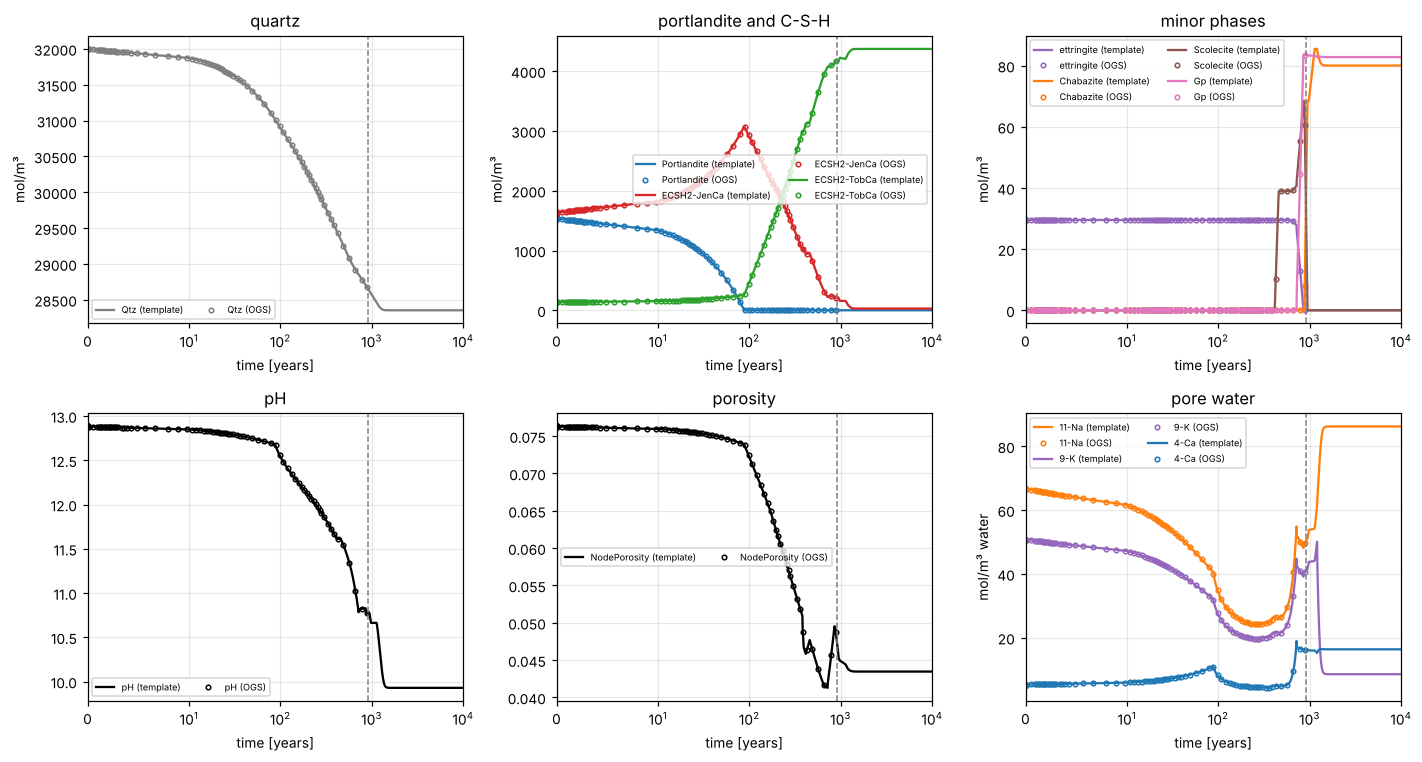

In [4]:
ref = {}
for xm, name in zip(monitor_x, ['node1', 'node10', 'node50', 'node100']):
    d = pd.read_csv(CASE / 'reference' / f'{name}.dat', sep=r'\s+', skiprows=1)
    d = d.sort_values('time').drop_duplicates('time').reset_index(drop=True).copy()
    d['time_yr'] = d['time'] / YR
    ref[xm] = d
ours, r = history[history.x_m == 5.0], ref[5.0]
panels = [('quartz', [('Qtz', 'Qtz', 'tab:gray')], 'mol/m³'),
          ('portlandite and C-S-H', [('Portlandite', 'Portlandite', 'tab:blue'), ('ECSH2-JenCa', 'ECSH2-JenCa', 'tab:red'),
                                     ('ECSH2-TobCa', 'ECSH2-TobCa', 'tab:green')], 'mol/m³'),
          ('minor phases', [('ettringite', 'ettringite', 'tab:purple'), ('Chabazite', 'Chabazite', 'tab:orange'),
                            ('Scolecite', 'Scolecite', 'tab:brown'), ('Gp', 'Gp', 'tab:pink')], 'mol/m³'),
          ('pH', [('pH', 'pH', 'k')], ''), ('porosity', [('porosity', 'NodePorosity', 'k')], ''),
          ('pore water', [('c_Na', '11-Na', 'tab:orange'), ('c_K', '9-K', 'tab:purple'), ('c_Ca', '4-Ca', 'tab:blue')], 'mol/m³ water')]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (title, series, unit) in zip(axes.flat, panels):
    for ok, rk, col in series:
        ax.plot(ours.time_yr, ours[ok], '-', color=col, label=f'{rk} (template)')
        ax.plot(r.time_yr[::4], r[rk][::4], 'o', ms=3, mfc='none', color=col, label=f'{rk} (OGS)')
    ax.axvline(r.time_yr.max(), color='0.5', ls='--', lw=1)
    ax.set_xscale('symlog', linthresh=10); ax.set_xlim(0, 10000)
    ax.set_title(title); ax.set_xlabel('time [years]'); ax.set_ylabel(unit); ax.legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.show()

下表在 OGS 的 351 个输出时刻比较全部 4 个监测节点（我们的时间序列插值到这些时刻）。nRMSE 是均方根误差除以 OGS 序列的变化幅度。

In [5]:
compare = [('Qtz', 'Qtz'), ('Portlandite', 'Portlandite'), ('ECSH2-JenCa', 'ECSH2-JenCa'), ('ECSH2-TobCa', 'ECSH2-TobCa'),
           ('ettringite', 'ettringite'), ('Chabazite', 'Chabazite'), ('Scolecite', 'Scolecite'), ('Gp', 'Gp'),
           ('pH', 'pH'), ('porosity', 'NodePorosity'), ('c_Si', '14-Si'), ('c_Ca', '4-Ca'), ('c_Na', '11-Na'), ('b_Cl', 'Cl')]
rows = []
for ok, rk in compare:
    worst = 0.0
    for xm in monitor_x:
        o_, rr = history[history.x_m == xm], ref[xm]
        a = np.interp(rr.time_yr.values, o_.time_yr.values, o_[ok].values)
        b = rr[rk].values
        if np.ptp(b) > 1e-9:
            worst = max(worst, 100 * np.sqrt(np.mean((a - b) ** 2)) / np.ptp(b))
    rows.append({'quantity': rk, 'OGS at 919 yr': ref[5.0][rk].values[-1],
                 'template at 919 yr': np.interp(ref[5.0].time_yr.values[-1], ours.time_yr, ours[ok]), 'nRMSE %': worst})
display(pd.DataFrame(rows).style.hide(axis='index').format({'OGS at 919 yr': '{:.5g}', 'template at 919 yr': '{:.5g}', 'nRMSE %': '{:.3f}'}))
for name in ['Portlandite', 'ettringite']:
    t_ours = ours.time_yr.values[np.argmax(ours[name].values < 1e-6)]
    t_ogs = r.time_yr.values[np.argmax(r[name].values < 1e-6)]
    print(f'{name} exhausted: template {t_ours:.0f} yr, OGS {t_ogs:.1f} yr (first OGS output with zero)')

quantity,OGS at 919 yr,template at 919 yr,nRMSE %
Qtz,28650,28649,0.035
Portlandite,0,0,0.037
ECSH2-JenCa,203.76,203.76,0.057
ECSH2-TobCa,4166.5,4166.5,0.050
ettringite,0,0,0.100
Chabazite,38.789,39.943,0.276
Scolecite,29.657,28.503,0.179
Gp,83.432,83.42,0.105
pH,10.767,10.767,0.044
NodePorosity,0.047048,0.046984,0.069


Portlandite exhausted: template 88 yr, OGS 88.7 yr (first OGS output with zero)
ettringite exhausted: template 858 yr, OGS 887.2 yr (first OGS output with zero)


## 复现时遇到的坑

1. **边界条件写在 `#STOP` 之后。** 直接看输入会以为是淋滤问题。OGS 读到第一个 `#STOP` 就停，所以柱子是封闭的。一定要确认 OGS 实际读了什么。
2. **每个节点的 H、O、Cl、Na、K 慢慢增加。** `$FLAG_COUPLING_HYDROLOGY 0` 时，消耗掉的水用当前成分的孔隙水补上。这是 OGS 的行为，不是误差。
3. **初始约束和钉住。** 没有石英下限，GEMS 会一下子把骨料全溶掉；第一遍之后不把动力学相钉住，第二遍也会这样。
4. **热启动会把石英卡住。** GEMS 热启动时石英停在旧上限；每次冷启动，和 OGS 一样（`$FLAG_GEM_USE_SIA 0`）。
5. **时间步。** OGS 用自适应步长 ≤ 10⁵ s；这里用 1 年。Portlandite 在 88 年耗尽（OGS 88.7 年）——剩下的差别大概来自时间步。
6. **气相扩散**（`$FLAG_GAS_DIFFUSION 1`）没做；这么高的 pH 下 GEMS 算不出 CO₂ 气体。
7. **919 年之后没有参考。** 1 万年的其余部分是预测。

## 练习

1. 用 `dt = 0.1` 年和 `dt = 5` 年各算 300 年。portlandite 耗尽的时刻移动了多少？
2. 去掉石英约束（`lower = 0`）。第一步 GEMS 对骨料做了什么？
3. 把 OGS 忽略掉的边界条件加回来：x = 0 处浓度固定为 `bench.bc` 里的值（`Transport(mesh, fixed_nodes=[...])`，
   `chem` 设 `boundary_nodes`）。1000 年里淋滤前锋推进多深？